# DSC 411/511 Project
# Notebook 02: Feature Reduction

**Class topic:** Lecture 04 (PCA, scree plot, loadings, scaling, filter methods for feature selection,
PCA vs feature selection head to head). Lecture 03, Section 10 (curse of dimensionality).

---

After cleaning we have about 50 candidate features, and more than 120 columns after one-hot encoding.
Lecture 03 showed that distances get less meaningful as dimensions grow (the curse of dimensionality),
and Lecture 04 showed two ways to fight it:

1. **Feature selection**: keep a subset of the original columns (they keep their meaning).
2. **Feature extraction (PCA)**: build new columns that are mixtures of the old ones.

We try both and compare them on the same model and the same target, like Lecture 04, Section 8.

---
# Section 0: Setup

In [1]:
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif, SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.inspection import permutation_importance
import lightgbm as lgb

sys.path.append('/Users/home/workspace/School/DataMining/nfip_claims')
from nfip_project_utils import *

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.width', 180)

claims = load_clean_claims()
train_claims = claims[claims['loss_year'].isin(TRAIN_YEARS)].copy()
test_claims = claims[claims['loss_year'].isin(TEST_YEARS)].copy()
print(f'Train rows (2020-2023): {len(train_claims):,}   Test rows (2024-2025): {len(test_claims):,}')

ALL_NUMERIC = NFIP_NUMERIC_FEATURES + EVENT_FEATURES + CONTEXT_FEATURES
check_no_leakage(ALL_NUMERIC + NFIP_CATEGORICAL_FEATURES)
print('Numeric candidate features   :', len(ALL_NUMERIC))
print('Categorical candidate features:', len(NFIP_CATEGORICAL_FEATURES))

Train rows (2020-2023): 147,642   Test rows (2024-2025): 105,482
Numeric candidate features   : 50
Categorical candidate features: 8


---
# Section 1: How Many Columns Do We Actually Have?

In [2]:
preprocessor = make_preprocessor(ALL_NUMERIC, NFIP_CATEGORICAL_FEATURES, scale=True)
train_matrix = preprocessor.fit_transform(train_claims)          # fit on TRAIN only
encoded_names = list(preprocessor.get_feature_names_out())
print(f'After one-hot encoding: {train_matrix.shape[1]} columns')
print('Example encoded names:', encoded_names[-12:])

After one-hot encoding: 116 columns
Example encoded names: ['state_NJ', 'state_NY', 'state_OH', 'state_PA', 'state_SC', 'state_TN', 'state_TX', 'state_VA', 'state_VT', 'state_WA', 'state_WV', 'state_infrequent_sklearn']


---
# Section 2: Filter 1: Drop Near-Constant Columns (VarianceThreshold)

A column that is almost always the same value cannot separate anything. We measure variance on the
**unscaled** 0/1 and numeric columns. For a 0/1 column, variance = p(1-p), so a threshold of 0.01
removes columns where one value covers more than about 99% of rows.

In [3]:
unscaled_preprocessor = make_preprocessor(ALL_NUMERIC, NFIP_CATEGORICAL_FEATURES, scale=False)
unscaled_train = pd.DataFrame(unscaled_preprocessor.fit_transform(train_claims), columns=encoded_names)
binary_columns = [c for c in unscaled_train.columns if set(np.unique(unscaled_train[c])) <= {0, 1}]
variance_filter = VarianceThreshold(threshold=0.01).fit(unscaled_train[binary_columns])
low_variance_columns = [c for c, keep in zip(binary_columns, variance_filter.get_support()) if not keep]
print(f'Binary columns checked: {len(binary_columns)}')
print(f'Near-constant binary columns (variance < 0.01): {len(low_variance_columns)}')
for column in low_variance_columns:
    print(f'   {column:<45} share of 1s = {unscaled_train[column].mean() * 100:.2f}%')

Binary columns checked: 79
Near-constant binary columns (variance < 0.01): 23
   construction_year_was_missing                 share of 1s = 0.30%
   floodproofedIndicator                         share of 1s = 0.00%
   flood_zone_group_A_protected_by_levee         share of 1s = 0.50%
   flood_zone_group_infrequent_sklearn           share of 1s = 0.05%
   occupancy_group_mobile_home                   share of 1s = 1.01%
   occupancy_group_unit_in_multi_unit_building   share of 1s = 0.97%
   floors_group_split_level                      share of 1s = 0.27%
   floors_group_infrequent_sklearn               share of 1s = 0.01%
   condominiumCoverageTypeCode_infrequent_sklearn share of 1s = 0.56%
   state_AR                                      share of 1s = 0.28%
   state_CT                                      share of 1s = 0.74%
   state_GA                                      share of 1s = 0.98%
   state_IL                                      share of 1s = 0.72%
   state_MA             

---
# Section 3: Filter 2: Drop One of Every Highly Correlated Pair

Two columns with |r| > 0.85 carry nearly the same information. Keeping both doubles their weight
in a distance and makes linear coefficients unstable.

In [4]:
correlation = train_claims[ALL_NUMERIC].corr(method='spearman')
high_pairs = []
for i, first in enumerate(ALL_NUMERIC):
    for second in ALL_NUMERIC[i + 1:]:
        value = correlation.loc[first, second]
        if abs(value) > 0.85:
            high_pairs.append({'feature_1': first, 'feature_2': second, 'spearman_r': round(value, 3)})
high_pairs_table = pd.DataFrame(high_pairs).sort_values('spearman_r', key=abs, ascending=False)
print(high_pairs_table.to_string(index=False))

                 feature_1                    feature_2  spearman_r
  storm_wind_at_closest_kt    storm_category_at_closest       0.986
  storm_wind_at_closest_kt storm_wind_proxy_at_claim_kt       0.952
              rain_3day_mm                 rain_7day_mm       0.947
 storm_category_at_closest storm_wind_proxy_at_claim_kt       0.945
              rain_7day_mm       rain_max_daily_7day_mm       0.917
              rain_3day_mm       rain_max_daily_7day_mm       0.915
storm_lifetime_max_wind_kt storm_wind_proxy_at_claim_kt       0.857
         storm_distance_km storm_wind_proxy_at_claim_kt      -0.854


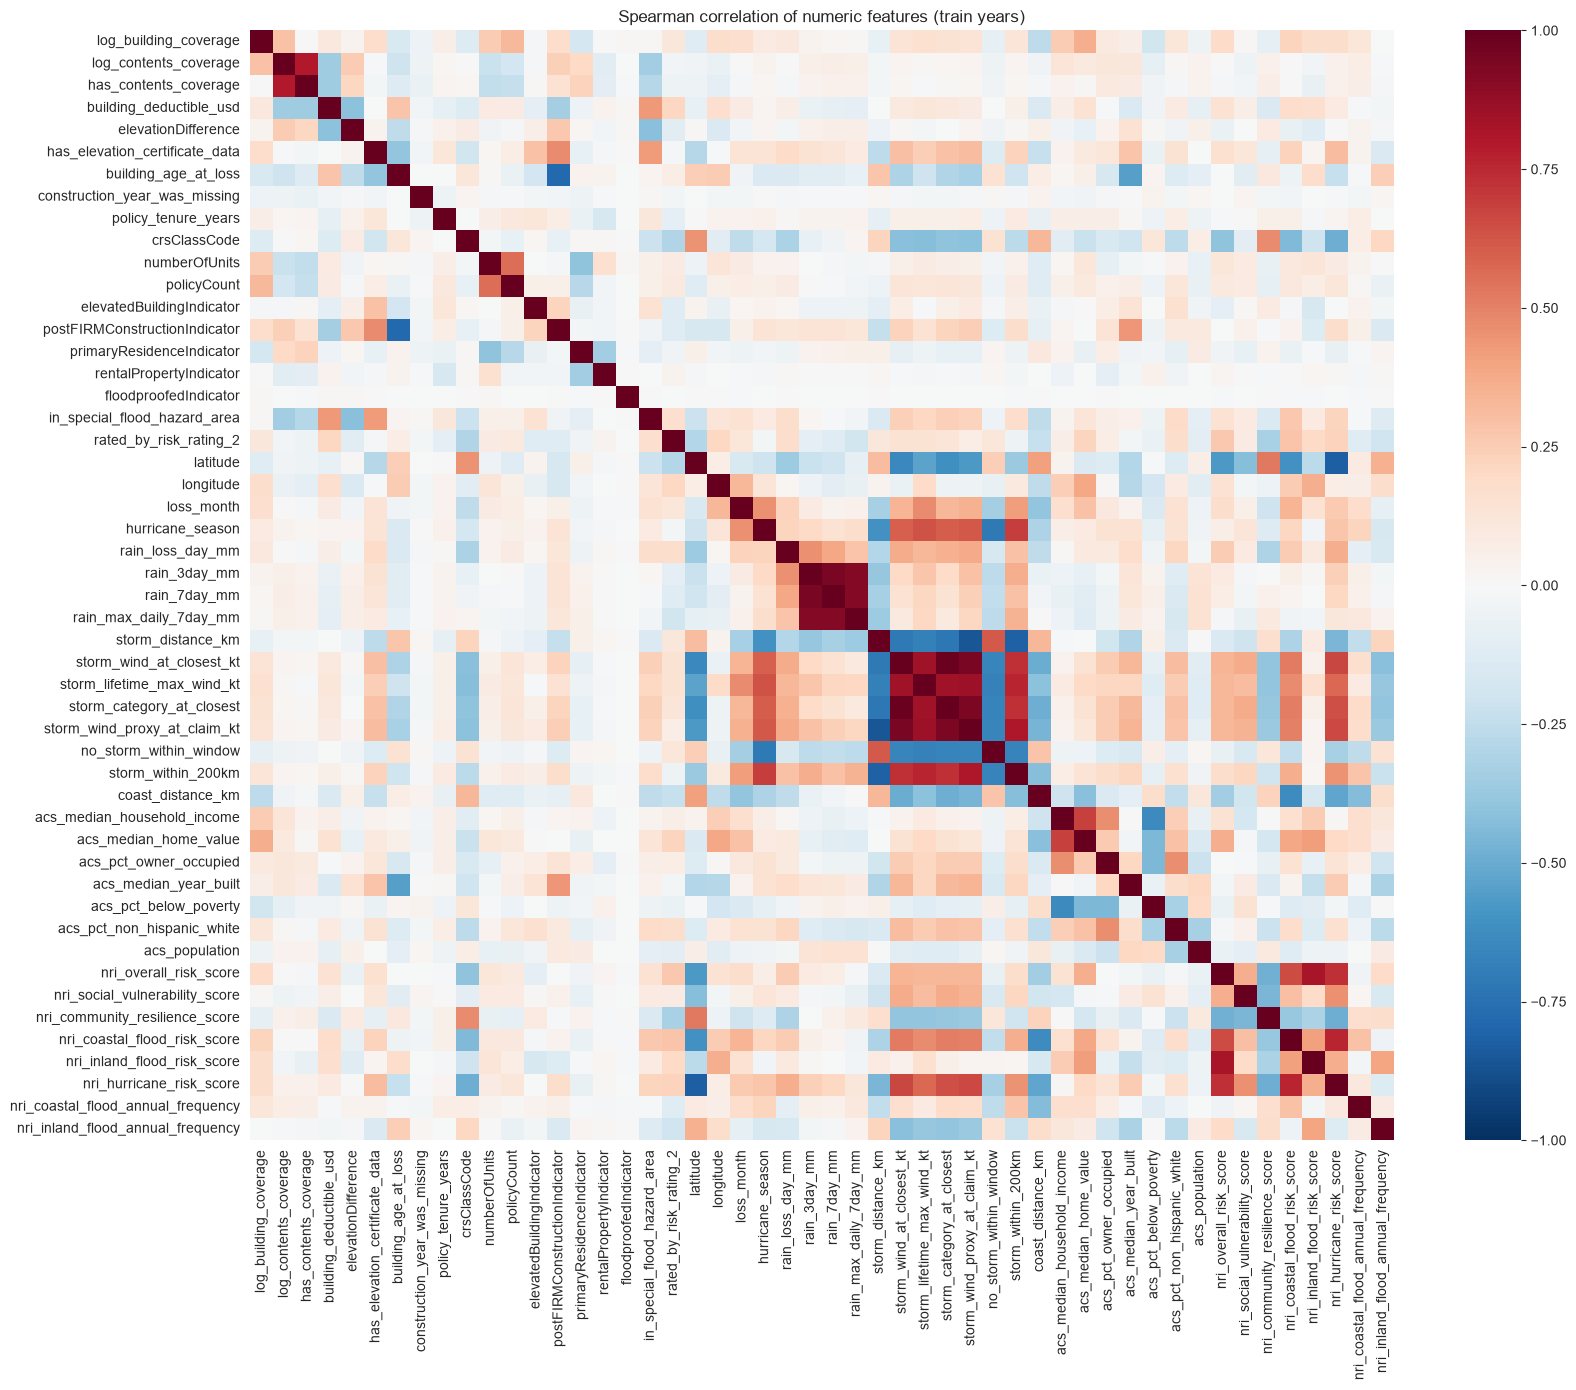

In [5]:
fig, ax = plt.subplots(figsize=(17, 14))
sns.heatmap(correlation, cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax, xticklabels=True, yticklabels=True)
ax.set_title('Spearman correlation of numeric features (train years)')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '02_correlation_heatmap.png', dpi=110)
plt.show()

**Which one of each pair do we keep?** The one that is easier to explain, or that has fewer missing
values. For example `rain_3day_mm` is kept over `rain_loss_day_mm` (the 3-day window is less sensitive
to PRISM's 12:00 UTC day boundary), and `storm_wind_proxy_at_claim_kt` is kept over raw wind.

In [6]:
correlated_to_drop = []
preferred_to_keep = ['rain_3day_mm', 'storm_wind_proxy_at_claim_kt', 'storm_distance_km', 'log_building_coverage',
                     'building_age_at_loss', 'acs_median_household_income', 'nri_coastal_flood_risk_score',
                     'latitude', 'rated_by_risk_rating_2']
for _, pair in high_pairs_table.iterrows():
    first, second = pair['feature_1'], pair['feature_2']
    if first in correlated_to_drop or second in correlated_to_drop:
        continue
    drop = second if first in preferred_to_keep else first if second in preferred_to_keep else second
    correlated_to_drop.append(drop)
print('Dropped by the correlation filter:', correlated_to_drop)
filtered_numeric = [c for c in ALL_NUMERIC if c not in correlated_to_drop]
print(f'Numeric features: {len(ALL_NUMERIC)} -> {len(filtered_numeric)}')

Dropped by the correlation filter: ['storm_category_at_closest', 'storm_wind_at_closest_kt', 'rain_7day_mm', 'rain_max_daily_7day_mm', 'storm_lifetime_max_wind_kt', 'storm_wind_proxy_at_claim_kt']
Numeric features: 50 -> 44


---
# Section 4: PCA on the Numeric Features

## 4.1 The idea in plain words

PCA rotates the data. The first new axis (PC1) points in the direction where the claims are
most spread out. PC2 is the most spread-out direction that is at 90 degrees to PC1, and so on.
Mathematically, the axes are the **eigenvectors of the covariance matrix**, and the eigenvalue of
each axis is the variance along it. "Explained variance ratio" = eigenvalue / sum of all eigenvalues.

## 4.2 Scaling is not optional (Lecture 04, Section 5)

In [7]:
numeric_train = train_claims[filtered_numeric].fillna(train_claims[filtered_numeric].median())
pca_unscaled = PCA().fit(numeric_train)
top_unscaled = pd.Series(np.abs(pca_unscaled.components_[0]), index=filtered_numeric).sort_values(ascending=False).head(3)
print(f'Without scaling, PC1 explains {pca_unscaled.explained_variance_ratio_[0] * 100:.1f}% of the variance.')
print('...and it is basically just these columns (largest weights):')
print(top_unscaled.round(3).to_string())
print('\nThose columns have the widest ranges (dollars and people), not the most information.')

Without scaling, PC1 explains 54.6% of the variance.
...and it is basically just these columns (largest weights):
acs_median_home_value          0.936
acs_population                 0.340
acs_median_household_income    0.088

Those columns have the widest ranges (dollars and people), not the most information.


Scaled PCA on 44 columns
   components for 80% of variance: 20
   components for 90% of variance: 28
   components for 95% of variance: 33


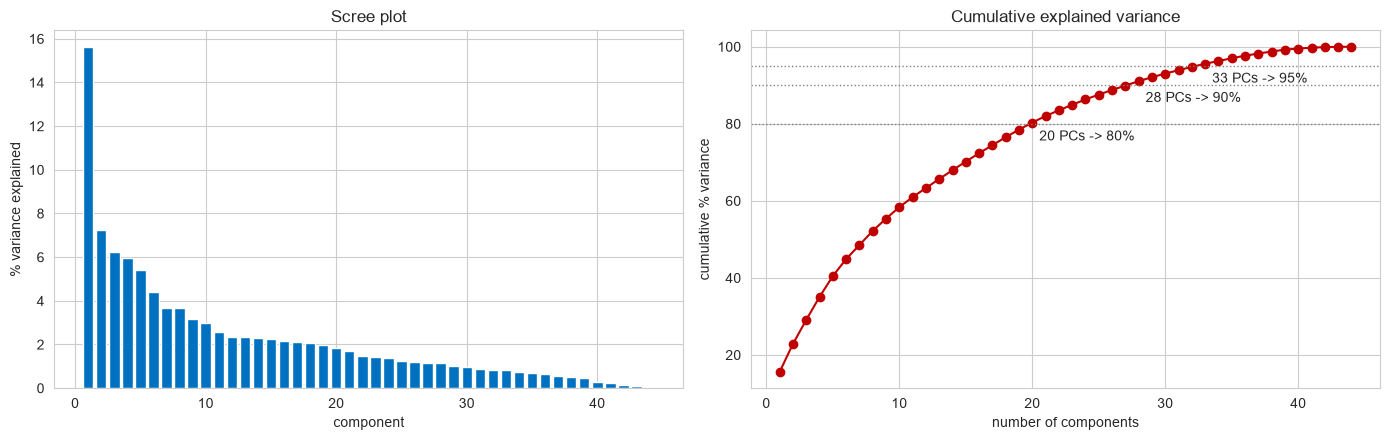

In [8]:
scaler = StandardScaler().fit(numeric_train)
numeric_train_scaled = scaler.transform(numeric_train)
pca = PCA(random_state=SEED).fit(numeric_train_scaled)
explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)
components_needed = {share: int(np.argmax(cumulative >= share) + 1) for share in [0.8, 0.9, 0.95]}
print(f'Scaled PCA on {len(filtered_numeric)} columns')
for share, count in components_needed.items():
    print(f'   components for {share * 100:.0f}% of variance: {count}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(range(1, len(explained) + 1), explained * 100, color='#0070C0')
axes[0].set_xlabel('component')
axes[0].set_ylabel('% variance explained')
axes[0].set_title('Scree plot')
axes[1].plot(range(1, len(cumulative) + 1), cumulative * 100, 'o-', color='#C00000')
for share, count in components_needed.items():
    axes[1].axhline(share * 100, color='grey', ls=':', lw=1)
    axes[1].annotate(f'{count} PCs -> {share * 100:.0f}%', (count, share * 100), textcoords='offset points', xytext=(5, -12))
axes[1].set_xlabel('number of components')
axes[1].set_ylabel('cumulative % variance')
axes[1].set_title('Cumulative explained variance')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '02_pca_scree.png', dpi=120)
plt.show()

**Reading the scree plot.** There is no sharp elbow. The variance is spread over many
components, which means the features are **not** strongly redundant. PCA cannot squeeze this data
into 2 or 3 numbers without losing most of it.

## 4.3 Reading the loadings (Lecture 04, Section 4)

PC1 (15.6%): storm_distance_km (+0.31), storm_within_200km (-0.30), nri_hurricane_risk_score (-0.29), nri_coastal_flood_risk_score (-0.28), coast_distance_km (+0.26), no_storm_within_window (+0.25)
PC2 (7.3%): building_age_at_loss (+0.35), acs_median_year_built (-0.33), postFIRMConstructionIndicator (-0.32), nri_inland_flood_risk_score (+0.31), nri_inland_flood_annual_frequency (+0.25), nri_overall_risk_score (+0.24)
PC3 (6.2%): acs_median_household_income (+0.44), acs_pct_below_poverty (-0.40), acs_pct_owner_occupied (+0.36), acs_median_home_value (+0.32), acs_pct_non_hispanic_white (+0.31), nri_social_vulnerability_score (-0.22)
PC4 (6.0%): has_contents_coverage (+0.34), log_contents_coverage (+0.33), in_special_flood_hazard_area (-0.29), acs_pct_non_hispanic_white (-0.25), rated_by_risk_rating_2 (-0.23), nri_community_resilience_score (+0.22)


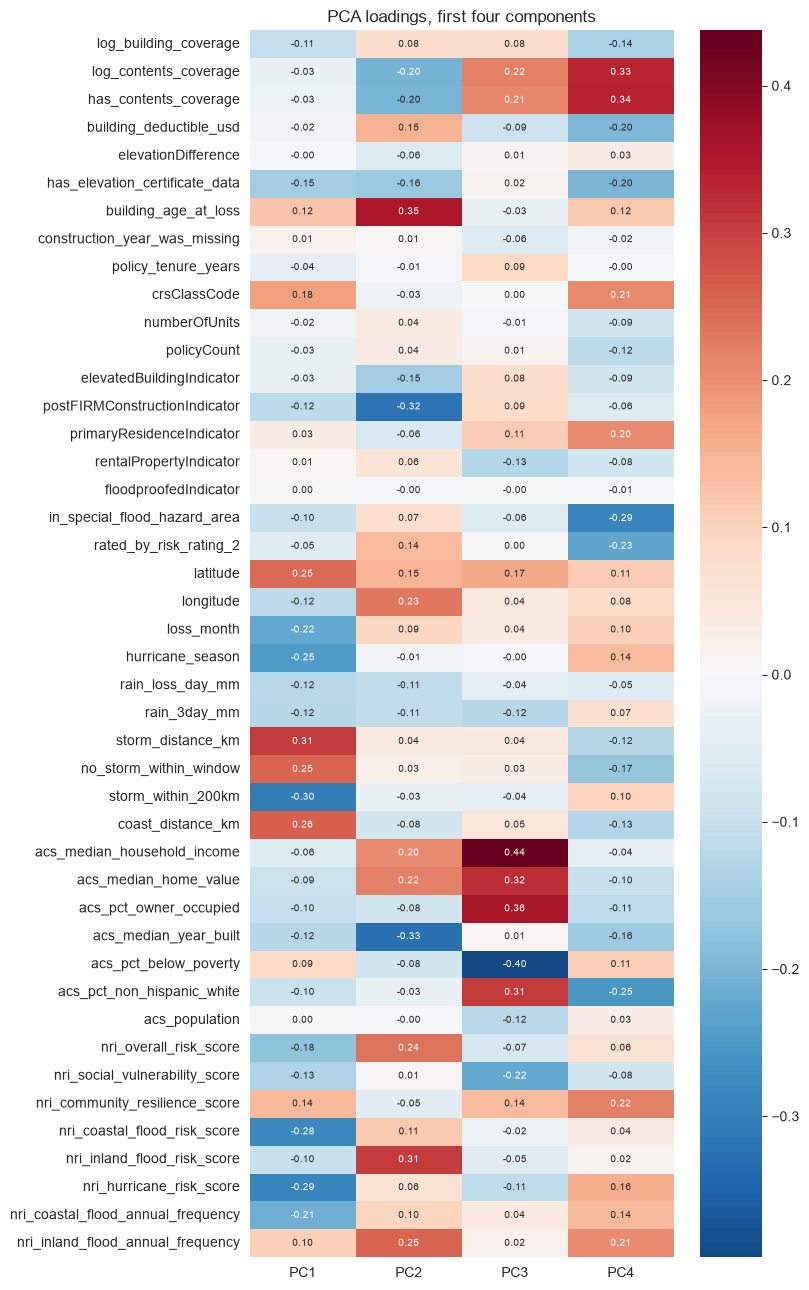

In [9]:
loadings = pd.DataFrame(pca.components_[:4].T, index=filtered_numeric, columns=['PC1', 'PC2', 'PC3', 'PC4'])
for component in loadings.columns:
    top = loadings[component].abs().sort_values(ascending=False).head(6).index
    print(f'{component} ({explained[int(component[2:]) - 1] * 100:.1f}%):',
          ', '.join(f'{name} ({loadings.loc[name, component]:+.2f})' for name in top))

fig, ax = plt.subplots(figsize=(8, 13))
sns.heatmap(loadings, cmap='RdBu_r', center=0, annot=True, fmt='.2f', ax=ax, annot_kws={'size': 7})
ax.set_title('PCA loadings, first four components')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '02_pca_loadings.png', dpi=120)
plt.show()

**Naming the components.** The loadings show whether each component is about storm exposure,
building size and policy, or neighbourhood wealth (see the printed lists above). These names come back
in the clustering notebook.

---
# Section 5: Filter 3: Rank Features by Their Relationship with the Target

We use two targets: **RQ1** (building paid > 0) and **RQ2** (large loss). Mutual information (MI)
measures how much knowing a feature reduces the uncertainty about the target. Unlike correlation,
MI also sees non-linear relationships. MI is computed on a 60,000-row sample of the **training years**.

**Lecture 04 warning:** ranking against the target is itself a use of the target. If we rank on the
whole data and then test on the same data, we leak. So we rank on train only.

In [10]:
mi_sample = train_claims.sample(60_000, random_state=SEED)
mi_input = mi_sample[filtered_numeric].fillna(train_claims[filtered_numeric].median())
mi_paid = mutual_info_classif(mi_input, mi_sample['building_paid_flag'], random_state=SEED)
large_loss_sample = mi_sample[mi_sample['large_loss_flag'].notna()]
mi_large = mutual_info_classif(large_loss_sample[filtered_numeric].fillna(train_claims[filtered_numeric].median()),
                               large_loss_sample['large_loss_flag'].astype(int), random_state=SEED)
mi_table = pd.DataFrame({'MI_with_building_paid': mi_paid, 'MI_with_large_loss': mi_large}, index=filtered_numeric)
mi_table['source'] = ['NFIP' if c in NFIP_NUMERIC_FEATURES else 'event (PRISM/HURDAT2/coast)' if c in EVENT_FEATURES
                      else 'context (ACS/NRI)' for c in mi_table.index]
mi_table = mi_table.sort_values('MI_with_large_loss', ascending=False)
mi_table.round(4).to_csv(TABLE_DIR / '02_mutual_information.csv')
print(mi_table.round(4).head(25).to_string())

                                    MI_with_building_paid  MI_with_large_loss                       source
acs_pct_non_hispanic_white                         0.0534              0.0711            context (ACS/NRI)
acs_median_household_income                        0.0531              0.0699            context (ACS/NRI)
acs_pct_owner_occupied                             0.0507              0.0683            context (ACS/NRI)
acs_pct_below_poverty                              0.0543              0.0656            context (ACS/NRI)
rain_loss_day_mm                                   0.0494              0.0629  event (PRISM/HURDAT2/coast)
acs_median_home_value                              0.0399              0.0629            context (ACS/NRI)
acs_population                                     0.0364              0.0619            context (ACS/NRI)
coast_distance_km                                  0.0493              0.0600  event (PRISM/HURDAT2/coast)
rain_3day_mm                         

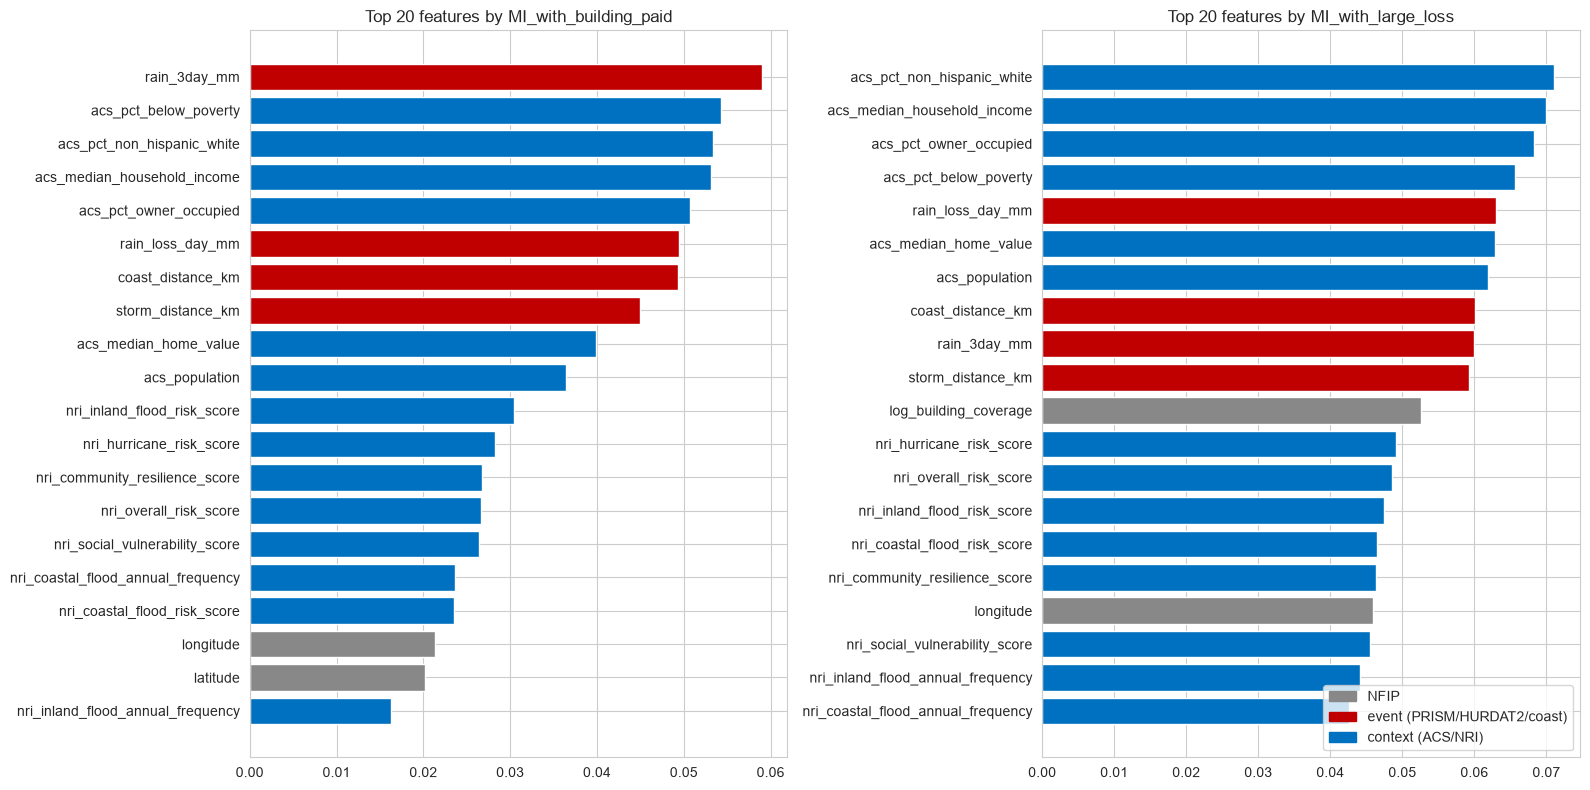

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
source_colors = {'NFIP': '#888888', 'event (PRISM/HURDAT2/coast)': '#C00000', 'context (ACS/NRI)': '#0070C0'}
for ax, column in zip(axes, ['MI_with_building_paid', 'MI_with_large_loss']):
    top = mi_table.sort_values(column, ascending=False).head(20).iloc[::-1]
    ax.barh(top.index, top[column], color=[source_colors[s] for s in top['source']])
    ax.set_title(f'Top 20 features by {column}')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in source_colors.values()]
axes[1].legend(handles, source_colors.keys(), loc='lower right')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '02_mutual_information.png', dpi=120)
plt.show()

In [12]:
mi_share_by_source = mi_table.groupby('source')[['MI_with_building_paid', 'MI_with_large_loss']].sum()
mi_share_by_source = (mi_share_by_source / mi_share_by_source.sum() * 100).round(1)
print('Share of total mutual information by data source (%):')
print(mi_share_by_source.to_string())

Share of total mutual information by data source (%):
                             MI_with_building_paid  MI_with_large_loss
source                                                                
NFIP                                          19.4                28.0
context (ACS/NRI)                             56.3                53.8
event (PRISM/HURDAT2/coast)                   24.3                18.2


**Two readings, one of them a warning.**
- The external event features (rain, storm distance, coast distance) rank high for both targets, even though they
  are only 12 columns. This is the first number that justifies the extra datasets.
- The ACS columns also rank high, but be careful: an ACS value is the same for every claim in a block group, so it
  works almost like a **location ID**. The k-NN based MI estimator rewards anything that identifies *where* a claim
  is, and in a few storms "where" largely decides "how bad". High MI here partly means "this column memorises places",
  which may not transfer to a new storm. The time-split tests in Section 7 and in notebooks 03-04 are the real judge.

---
# Section 6: Model-Based Selection: Permutation Importance

Filter methods look at one feature at a time. A model sees features **together**. Permutation importance
shuffles one column on held-out data and measures how much the score drops. A big drop means the
model really needed that column. We use LightGBM (a gradient-boosted tree model) for the large-loss target
and a 2023 hold-out year.

In [13]:
model_numeric = filtered_numeric
model_categorical = NFIP_CATEGORICAL_FEATURES
damage_known = claims['large_loss_flag'].notna()
fit_rows = claims[damage_known & claims['loss_year'].isin([2020, 2021, 2022])]
holdout_rows = claims[damage_known & (claims['loss_year'] == 2023)]
lightgbm_model = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                                    colsample_bytree=0.8, random_state=SEED, verbose=-1)
lightgbm_model.fit(to_category_frame(fit_rows, model_numeric, model_categorical), fit_rows['large_loss_flag'].astype(int))
holdout_frame = to_category_frame(holdout_rows, model_numeric, model_categorical)
holdout_sample = holdout_frame.sample(min(12_000, len(holdout_frame)), random_state=SEED)
permutation = permutation_importance(lightgbm_model, holdout_sample, holdout_rows.loc[holdout_sample.index, 'large_loss_flag'].astype(int),
                                     scoring='average_precision', n_repeats=3, random_state=SEED, n_jobs=1)
permutation_table = pd.DataFrame({'importance_mean': permutation.importances_mean, 'importance_std': permutation.importances_std},
                                 index=holdout_sample.columns).sort_values('importance_mean', ascending=False)
permutation_table.round(4).to_csv(TABLE_DIR / '02_permutation_importance_large_loss.csv')
print(permutation_table.head(20).round(4).to_string())

                                importance_mean  importance_std
log_building_coverage                    0.1698          0.0063
rain_3day_mm                             0.0388          0.0057
occupancy_group                          0.0240          0.0066
numberOfUnits                            0.0236          0.0004
foundation_group                         0.0198          0.0017
elevationDifference                      0.0129          0.0008
basement_group                           0.0125          0.0029
building_age_at_loss                     0.0099          0.0006
building_deductible_usd                  0.0082          0.0019
acs_pct_owner_occupied                   0.0071          0.0006
in_special_flood_hazard_area             0.0066          0.0016
log_contents_coverage                    0.0060          0.0031
primaryResidenceIndicator                0.0040          0.0032
acs_pct_below_poverty                    0.0039          0.0013
crsClassCode                            

---
# Section 7: PCA vs Feature Selection, Head to Head (Lecture 04, Section 8)

Same model (logistic regression), same target (large loss), same time split (train 2020-2023,
test 2024-2025). Only the inputs change.

In [14]:
train_large = claims[damage_known & claims['loss_year'].isin(TRAIN_YEARS)]
test_large = claims[damage_known & claims['loss_year'].isin(TEST_YEARS)]
train_target = train_large['large_loss_flag'].astype(int)
test_target = test_large['large_loss_flag'].astype(int)
medians = train_large[ALL_NUMERIC].median()


def evaluate_logistic(train_matrix, test_matrix, description, n_columns):
    model = LogisticRegression(max_iter=2000, class_weight='balanced')
    model.fit(train_matrix, train_target)
    scores = model.predict_proba(test_matrix)[:, 1]
    return {'inputs': description, 'n_columns': n_columns, 'test_ROC_AUC': round(roc_auc_score(test_target, scores), 4),
            'test_PR_AUC': round(average_precision_score(test_target, scores), 4)}


head_to_head = []
all_scaler = StandardScaler().fit(train_large[ALL_NUMERIC].fillna(medians))
train_all = all_scaler.transform(train_large[ALL_NUMERIC].fillna(medians))
test_all = all_scaler.transform(test_large[ALL_NUMERIC].fillna(medians))
head_to_head.append(evaluate_logistic(train_all, test_all, 'all numeric features', len(ALL_NUMERIC)))

filtered_index = [ALL_NUMERIC.index(c) for c in filtered_numeric]
head_to_head.append(evaluate_logistic(train_all[:, filtered_index], test_all[:, filtered_index],
                                      'after variance + correlation filters', len(filtered_numeric)))

top_mi_features = mi_table.sort_values('MI_with_large_loss', ascending=False).head(15).index.tolist()
top_mi_index = [ALL_NUMERIC.index(c) for c in top_mi_features]
head_to_head.append(evaluate_logistic(train_all[:, top_mi_index], test_all[:, top_mi_index], 'top 15 by mutual information', 15))

nfip_only_index = [ALL_NUMERIC.index(c) for c in NFIP_NUMERIC_FEATURES]
head_to_head.append(evaluate_logistic(train_all[:, nfip_only_index], test_all[:, nfip_only_index], 'NFIP numeric only (no external)', len(NFIP_NUMERIC_FEATURES)))

for n_components in [5, 10, components_needed[0.9]]:
    pca_model = PCA(n_components=n_components, random_state=SEED).fit(train_all[:, filtered_index])
    head_to_head.append(evaluate_logistic(pca_model.transform(train_all[:, filtered_index]),
                                          pca_model.transform(test_all[:, filtered_index]),
                                          f'PCA, {n_components} components', n_components))
head_to_head_table = pd.DataFrame(head_to_head)
head_to_head_table.to_csv(TABLE_DIR / '02_pca_vs_selection.csv', index=False)
print(f'Test positives: {test_target.mean() * 100:.1f}% (PR-AUC of a random model = this share)')
print(head_to_head_table.to_string(index=False))

Test positives: 17.0% (PR-AUC of a random model = this share)
                              inputs  n_columns  test_ROC_AUC  test_PR_AUC
                all numeric features         50        0.7484       0.3335
after variance + correlation filters         44        0.7831       0.3779
        top 15 by mutual information         15        0.7479       0.3304
     NFIP numeric only (no external)         23        0.7677       0.3661
                   PCA, 5 components          5        0.6570       0.2604
                  PCA, 10 components         10        0.7232       0.3161
                  PCA, 28 components         28        0.7670       0.3611


**Reading the head-to-head** (logistic regression, large-loss target, test years 2024-2025, 17.1% positives).
- **Filtering helps a linear model.** After the variance and correlation filters (44 columns) the test
  ROC-AUC rises from 0.750 to 0.782 and PR-AUC from 0.336 to 0.377. Correlated rain/storm copies confuse
  the coefficients, so removing them helps.
- **The top 15 by mutual information (0.753) are no better than all features.** MI ranked ACS columns
  high, but for a linear model they add little.
- **PCA loses information:** 5 components give 0.652 and 10 give 0.730. Even 28 components (90% of the
  variance) reach only 0.767. The variance PCA keeps is not the variance that predicts the target.
- **NFIP numeric only (0.768) is almost as good as all features (0.750-0.782) for a *linear* model.** This is
  an honest, important result: a straight line cannot use rain or storm distance well, because their effect
  is not linear (threshold effects). The tree models in notebooks 03 and 04 test this again, and there the
  external data does help.

---
# Section 8: Save the Reduced Feature Lists

In [15]:
reduced_features = {
    'dropped_by_variance_filter': low_variance_columns,
    'dropped_by_correlation_filter': correlated_to_drop,
    'numeric_after_filters': filtered_numeric,
    'top15_mutual_information_large_loss': top_mi_features,
    'top15_mutual_information_building_paid': mi_table.sort_values('MI_with_building_paid', ascending=False).head(15).index.tolist(),
    'pca_components_for_90pct_variance': components_needed[0.9],
}
json.dump(reduced_features, open(TABLE_DIR / '02_reduced_feature_lists.json', 'w'), indent=2)
print(json.dumps(reduced_features, indent=2))

{
  "dropped_by_variance_filter": [
    "construction_year_was_missing",
    "floodproofedIndicator",
    "flood_zone_group_A_protected_by_levee",
    "flood_zone_group_infrequent_sklearn",
    "occupancy_group_mobile_home",
    "occupancy_group_unit_in_multi_unit_building",
    "floors_group_split_level",
    "floors_group_infrequent_sklearn",
    "condominiumCoverageTypeCode_infrequent_sklearn",
    "state_AR",
    "state_CT",
    "state_GA",
    "state_IL",
    "state_MA",
    "state_MD",
    "state_ME",
    "state_MI",
    "state_MO",
    "state_OH",
    "state_VA",
    "state_VT",
    "state_WA",
    "state_WV"
  ],
  "dropped_by_correlation_filter": [
    "storm_category_at_closest",
    "storm_wind_at_closest_kt",
    "rain_7day_mm",
    "rain_max_daily_7day_mm",
    "storm_lifetime_max_wind_kt",
    "storm_wind_proxy_at_claim_kt"
  ],
  "numeric_after_filters": [
    "log_building_coverage",
    "log_contents_coverage",
    "has_contents_coverage",
    "building_deductible_usd"

---
# Research Question (Notebook 02)

> **Can the claim features be reduced to a few dimensions without losing predictive value, and which data
> source carries the most information?**

**Answer.**
- **Not to a few PCA dimensions.** Scaled PCA needs 20 / 28 / 33 of 44 components for 80 / 90 / 95% of the
  variance, and 5 or 10 components lose clear predictive value (ROC 0.65 and 0.73 vs 0.78). The first
  components have clear meanings: PC1 = storm and coast exposure, PC2 = building age (old, inland),
  PC3 = neighbourhood wealth, PC4 = contents coverage and primary residence.
- **Yes, by selection.** The variance and correlation filters remove 6 redundant storm/rain columns
  (and the near-constant ones) and improve a linear model.
- **Which source carries information?** By mutual information, ACS/NRI context holds about 54-55% of the
  total and event data 18-25%. But context values act partly like location codes. With a linear model,
  NFIP-only features do about as well as everything. So the real value of the external data must be tested
  with non-linear models and a time split. That is the job of notebooks 03 and 04.